მონაცემთა შესწავლა

In [21]:
import torch
import matplotlib.pyplot as plt
from pathlib import Path
import os
from torchvision import datasets



root_path=Path.cwd()
root_path

WindowsPath('c:/Users/Shalva/Desktop/machine_learnings/food')

In [26]:

root_path=Path.cwd() / 'data' / 'food-101' / 'images'

data = datasets.ImageFolder(root=root_path)

data.classes

['apple_pie',
 'baby_back_ribs',
 'baklava',
 'beef_carpaccio',
 'beef_tartare',
 'beet_salad',
 'beignets',
 'bibimbap',
 'bread_pudding',
 'breakfast_burrito',
 'bruschetta',
 'caesar_salad',
 'cannoli',
 'caprese_salad',
 'carrot_cake',
 'ceviche',
 'cheese_plate',
 'cheesecake',
 'chicken_curry',
 'chicken_quesadilla',
 'chicken_wings',
 'chocolate_cake',
 'chocolate_mousse',
 'churros',
 'clam_chowder',
 'club_sandwich',
 'crab_cakes',
 'creme_brulee',
 'croque_madame',
 'cup_cakes',
 'deviled_eggs',
 'donuts',
 'dumplings',
 'edamame',
 'eggs_benedict',
 'escargots',
 'falafel',
 'filet_mignon',
 'fish_and_chips',
 'foie_gras',
 'french_fries',
 'french_onion_soup',
 'french_toast',
 'fried_calamari',
 'fried_rice',
 'frozen_yogurt',
 'garlic_bread',
 'gnocchi',
 'greek_salad',
 'grilled_cheese_sandwich',
 'grilled_salmon',
 'guacamole',
 'gyoza',
 'hamburger',
 'hot_and_sour_soup',
 'hot_dog',
 'huevos_rancheros',
 'hummus',
 'ice_cream',
 'lasagna',
 'lobster_bisque',
 'lobster

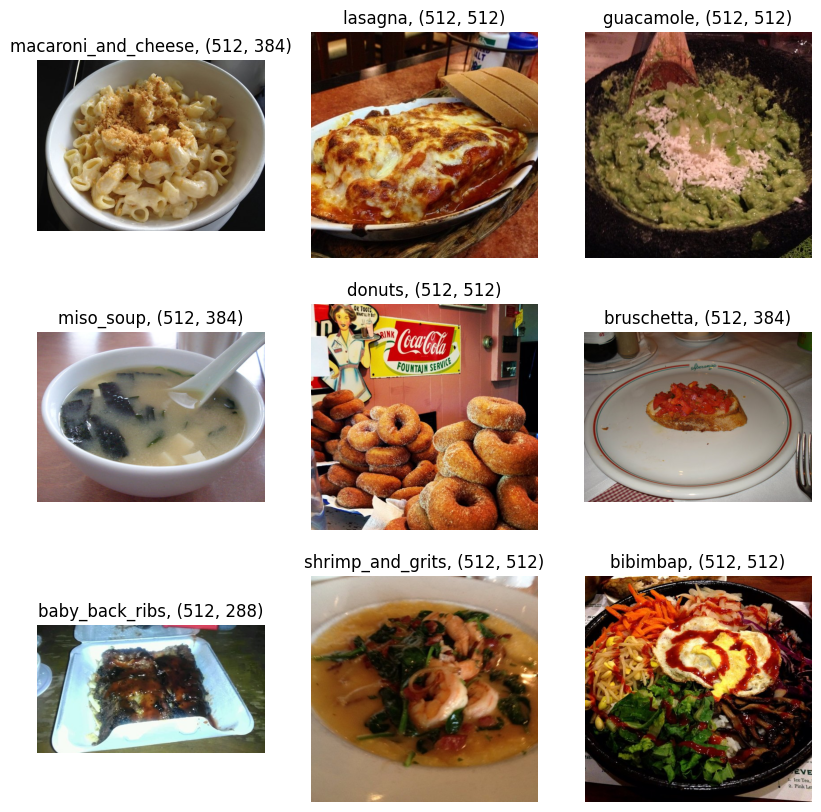

In [ ]:
import torch
import matplotlib.pyplot as plt
from pathlib import Path
import os
from torchvision import datasets


root_path=Path.cwd() / 'data' / 'food-101' / 'images'

data = datasets.ImageFolder(root=root_path)


torch.manual_seed(2)

fig=plt.figure(figsize=(10,10))
rows=3
cols=3


for i in range(1, rows*cols+1):
  random_idx=int(torch.randint(1,len(data), size=[1]).item())
  image,labels=data[random_idx]
  fig.add_subplot(rows, cols, i)
  plt.imshow(image)
  plt.title(f'{data.classes[labels]}, {image.size}')
  plt.axis(False)


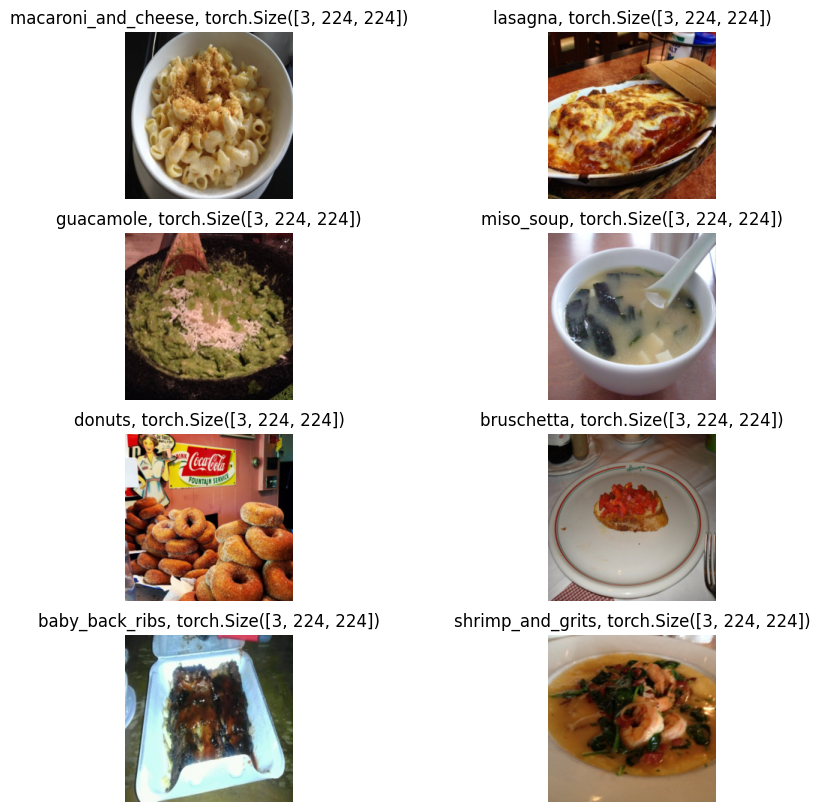

In [54]:
import torch
import matplotlib.pyplot as plt
from pathlib import Path
import os
from torchvision import datasets, transforms


root_path=Path.cwd() / 'data' / 'food-101' / 'images'

shape_size=(224,224)

transform = transforms.Compose([
  transforms.Resize(shape_size),
  transforms.ToTensor()

])


data = datasets.ImageFolder(root=root_path, transform=transform)


torch.manual_seed(2)

fig=plt.figure(figsize=(10,10))
rows=4
cols=2


for i in range(1, rows*cols+1):
  random_idx=int(torch.randint(1,len(data), size=[1]).item())
  image,labels=data[random_idx]
  image.shape

  fig.add_subplot(rows, cols, i)
  plt.imshow(image.permute(1,2,0))
  plt.title(f'{data.classes[labels]}, {image.shape}')
  plt.axis(False)


In [45]:
len(data)

101000

In [ ]:

from pathlib import Path
import mlflow

output=Path("experiments_export.csv")

runs=mlflow.search_runs(
    search_all_experiments=True,
    max_results=100000
)

if runs.empty:
    print("No MLflow runs found. Check the tracking URI.")
else:
    runs.to_csv(output, index=False)
    print(f"Exported {len(runs)} runs to {output.resolve()}")
    print("Columns:", runs.columns.tolist())


Delete 50 % of data from all classes (to reduce the size)

In [4]:

from pathlib import Path
import random

DATA_DIR=Path(r"C:\Users\Shalva\Desktop\machine_learnings\food\data\food-101\images")
SEED=42
APPLY=True

rng=random.Random(SEED)
classes=sorted(p for p in DATA_DIR.iterdir() if p.is_dir())
total_before=total_after=0

if len(classes)!=101:
    raise RuntimeError(f"Expected 101 classes, found {len(classes)}")

for folder in classes:
    images=sorted(p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in {".jpg",".jpeg",".png"})
    rng.shuffle(images)
    keep=(len(images)+1)//2
    remove=images[keep:]
    total_before+=len(images)
    total_after+=keep

    if APPLY:
        for image in remove:
            image.unlink()

    print(f"{folder.name}: {len(images)} -> {keep}")

print(f"\nClasses: {len(classes)}")
print(f"Images before: {total_before:,}")
print(f"Images remaining: {total_after:,}")
print(f"Images {'deleted' if APPLY else 'to delete'}: {total_before-total_after:,}")
print("DRY RUN: no files deleted." if not APPLY else "Deletion complete.")


apple_pie: 1000 -> 500
baby_back_ribs: 1000 -> 500
baklava: 1000 -> 500
beef_carpaccio: 1000 -> 500
beef_tartare: 1000 -> 500
beet_salad: 1000 -> 500
beignets: 1000 -> 500
bibimbap: 1000 -> 500
bread_pudding: 1000 -> 500
breakfast_burrito: 1000 -> 500
bruschetta: 1000 -> 500
caesar_salad: 1000 -> 500
cannoli: 1000 -> 500
caprese_salad: 1000 -> 500
carrot_cake: 1000 -> 500
ceviche: 1000 -> 500
cheese_plate: 1000 -> 500
cheesecake: 1000 -> 500
chicken_curry: 1000 -> 500
chicken_quesadilla: 1000 -> 500
chicken_wings: 1000 -> 500
chocolate_cake: 1000 -> 500
chocolate_mousse: 1000 -> 500
churros: 1000 -> 500
clam_chowder: 1000 -> 500
club_sandwich: 1000 -> 500
crab_cakes: 1000 -> 500
creme_brulee: 1000 -> 500
croque_madame: 1000 -> 500
cup_cakes: 1000 -> 500
deviled_eggs: 1000 -> 500
donuts: 1000 -> 500
dumplings: 1000 -> 500
edamame: 1000 -> 500
eggs_benedict: 1000 -> 500
escargots: 1000 -> 500
falafel: 1000 -> 500
filet_mignon: 1000 -> 500
fish_and_chips: 1000 -> 500
foie_gras: 1000 -> 50

In [5]:
import pandas as pd
import plotly.express as px

csv_path = r"C:\Users\Shalva\Desktop\machine_learnings\food\zenml_model_comparison.csv"
df = pd.read_csv(csv_path)

# გამოიყენე მხოლოდ დასრულებული გაშვებები, თუ status სვეტი არსებობს
if "status" in df.columns:
    df = df[df["status"].astype(str).str.lower().str.contains("completed")].copy()

df["epochs"] = pd.to_numeric(df["epochs"], errors="coerce")
df["final_acc"] = pd.to_numeric(df["final_acc"], errors="coerce")
df = df.dropna(subset=["epochs", "final_acc", "model_name"])

df["accuracy_percent"] = df["final_acc"] * 100

# თუ CSV-ში რეალური ხანგრძლივობა მოგვიანებით დაემატება, გამოიყენებს მას.
duration_columns = [
    "processing_time_seconds",
    "training_time_seconds",
    "duration_seconds",
]
duration_col = next((c for c in duration_columns if c in df.columns), None)

if duration_col:
    df[duration_col] = pd.to_numeric(df[duration_col], errors="coerce")
    df = df.dropna(subset=[duration_col])
    z_column = duration_col
    z_label = "ტრენინგის დრო (წამი)"
else:
    # ამჟამინდელ CSV-ში არის გაშვების შექმნის დრო, მაგრამ არა ხანგრძლივობა.
    df["created"] = pd.to_datetime(df["created"], errors="coerce")
    df = df.dropna(subset=["created"])
    df["hours_after_first_run"] = (
        df["created"] - df["created"].min()
    ).dt.total_seconds() / 3600

    z_column = "hours_after_first_run"
    z_label = "გაშვების შექმნის დრო (საათი, პირველი run-იდან)"
    print("CSV-ში processing time არ არის; Z ღერძზე ნაჩვენებია run-ის შექმნის დრო.")

fig = px.scatter_3d(
    df,
    x="epochs",
    y="accuracy_percent",
    z=z_column,
    color="model_name",
    text="run_name",  # run-ის სახელი გამოჩნდება წერტილთან
    hover_name="run_name",
    hover_data=[
        c for c in ["training_proc_unit", "learning_rate", "final_f1"]
        if c in df.columns
    ],
    labels={
        "epochs": "Epoch-ების რაოდენობა",
        "accuracy_percent": "Accuracy (%)",
        z_column: z_label,
        "model_name": "მოდელი",
    },
    title="Food-101 მოდელების შედარება",
)

fig.update_traces(
    textposition="top center",
    textfont_size=9,
    marker=dict(size=6, opacity=0.85),
)
fig.update_layout(height=750)
fig.show()

CSV-ში processing time არ არის; Z ღერძზე ნაჩვენებია run-ის შექმნის დრო.
